<a href="https://colab.research.google.com/github/kd1018/0506/blob/main/notebooks/Upscale_Images_with_Pretrained_super_image_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Upscale Images with Pre-trained `super-image` Models

---

[Github](https://github.com/eugenesiow/super-image) | All Models @ [huggingface.co](https://huggingface.co/models?filter=super-image)

---

Notebook to use the `super-image` library to quickly upscale and image.

The technique used is applying a pre-trained deep-learning model to restore a high resolution (HR) image from a single low resolution (LR) image. This is also called image super resolution.

The notebook is structured as follows:
* Setting up the Environment
* Using the Model (Running Inference)

## Setting up the Environment

#### Install the library

We will install the `super-image` library using `pip install`.

In [10]:
!pip install -qq super-image

## Using the Model (Running Inference)

Next we run a few lines of code to:

* `Image.open` and `requests.get` - Download an image from a URL (website) and store this as the `image` variable.
* `EdsrModel.from_pretrained` - Download and load a small, pre-trained deep-learning model to the `model` variable.
* `ImageLoader.load_image` - Load the image into the `model` using the `ImageLoader` helper.
* Use the model to run inference on the image (`inputs`).
* `ImageLoader.save_image` - Save the upscaled image output as a `.png` file using the `ImageLoader` helper.
* `ImageLoader.save_compare` - Save a `.png` that compares our upscaled image from the model with a baseline image using `Bicubic` upscaling.

### Upload and Upscale Your Own Photo

Run the cell below to select an image from your computer, upload it, and upscale it using the pre-trained model.

In [21]:
from google.colab import files
from PIL import Image
from super_image import EdsrModel, ImageLoader
import os
import math
import torch
import requests
import io
import urllib.parse
from tqdm.notebook import tqdm
from concurrent.futures import ThreadPoolExecutor

# --- CHOOSE MODE ---
print("Choose how you want to get your source image:")
print("1. Generate a new image using an AI Prompt (Free High-Resolution Models)")
print("2. Upload a local image from your computer")
mode = input("Enter choice (1 or 2): ").strip()

image_orig = None
has_alpha = False

if mode == '1':
    prompt = input("Enter your image prompt (in English): ").strip()
    if not prompt:
        prompt = "Vintage nostalgic t-shirt graphic badge"

    print("\nSelect the AI Image Generation Model:")
    print("1. Flux Model (Via Pollinations - Best for text, photorealism, and rich details)")
    print("2. Stable Diffusion XL (Via Pollinations - Excellent for artistic & retro styles)")
    print("3. Stable Diffusion 2.1 (Via Hugging Face API)")
    model_choice = input("Enter model choice (1, 2, or 3): ").strip()

    encoded_prompt = urllib.parse.quote(prompt)

    if model_choice == '1':
        print(f"Generating image with Flux model for prompt: '{prompt}'...")
        API_URL = f"https://image.pollinations.ai/p/{encoded_prompt}?width=1024&height=1024&nologo=true&model=flux"
    elif model_choice == '2':
        print(f"Generating image with SDXL model for prompt: '{prompt}'...")
        API_URL = f"https://image.pollinations.ai/p/{encoded_prompt}?width=1024&height=1024&nologo=true&model=turbo"
    else:
        print(f"Generating image with SD 2.1 model for prompt: '{prompt}'...")
        API_URL = "https://api-inference.huggingface.co/models/stabilityai/stable-diffusion-2-1"

    # Fetch image with automatic fallbacks in case of network or rate limits
    try:
        if model_choice in ['1', '2']:
            response = requests.get(API_URL, timeout=30)
        else:
            response = requests.post(API_URL, json={"inputs": prompt}, timeout=15)

        if response.status_code == 200:
            image_orig = Image.open(io.BytesIO(response.content))
            image_orig.save("generated_image.png")
            print("Image successfully generated and saved!")
        else:
            raise ConnectionError(f"API responded with status code: {response.status_code}")
    except Exception as e:
        print(f"Selected engine failed or timed out ({e}). Attempting fast fallback to general Pollinations engine...")
        try:
            fallback_api = f"https://image.pollinations.ai/p/{encoded_prompt}?width=1024&height=1024&nologo=true"
            res = requests.get(fallback_api, timeout=20)
            if res.status_code == 200:
                image_orig = Image.open(io.BytesIO(res.content))
                image_orig.save("generated_image.png")
                print("Image successfully generated via fallback engine!")
            else:
                raise ConnectionError()
        except Exception:
            print("All active generative engines failed. Using high-quality placeholder...")
            fallback_url = "https://images.unsplash.com/photo-1579783902614-a3fb3927b6a5?auto=format&fit=crop&w=600&q=80"
            res = requests.get(fallback_url, timeout=15)
            if res.status_code == 200:
                image_orig = Image.open(io.BytesIO(res.content))
                image_orig.save("generated_image.png")

elif mode == '2':
    uploaded = files.upload()
    if uploaded:
        original_filename = list(uploaded.keys())[0]
        print(f"Successfully uploaded {original_filename}")
        temp_filename = "input_image.png"
        if os.path.exists(temp_filename):
            os.remove(temp_filename)
        os.rename(original_filename, temp_filename)
        image_orig = Image.open(temp_filename)

if image_orig:
    width, height = image_orig.size
    has_alpha = 'A' in image_orig.getbands()
    image_rgb = image_orig.convert('RGB')

    # Ensure the model is loaded safely
    print("Loading EDSR model...")
    model = EdsrModel.from_pretrained('eugenesiow/edsr-base', scale=2)

    # Define patch size and overlap to avoid edge artifacts
    patch_size = 300
    overlap = 32
    scale = 2

    # Calculate number of patches in both dimensions
    stride = patch_size - overlap
    cols = math.ceil((width - overlap) / stride) if width > patch_size else 1
    rows = math.ceil((height - overlap) / stride) if height > patch_size else 1

    print(f"Original Image Size: {width}x{height}")
    print(f"Processing image in {rows}x{cols} ({rows * cols}) patches in PARALLEL...")

    # Create an empty canvas for the upscaled output
    output_width = width * scale
    output_height = height * scale
    upscaled_canvas = Image.new('RGB', (output_width, output_height))

    # Prepare patches data
    patches_tasks = []
    for r in range(rows):
        for c in range(cols):
            x1 = c * stride
            y1 = r * stride
            x2 = min(x1 + patch_size, width)
            y2 = min(y1 + patch_size, height)

            if x2 - x1 < patch_size and x1 > 0:
                x1 = max(0, x2 - patch_size)
            if y2 - y1 < patch_size and y1 > 0:
                y1 = max(0, y2 - patch_size)

            patches_tasks.append((r, c, x1, y1, x2, y2))

    # Define a helper function to process a single patch safely
    def process_patch(task):
        r, c, x1, y1, x2, y2 = task
        patch = image_rgb.crop((x1, y1, x2, y2))
        inputs = ImageLoader.load_image(patch)
        with torch.no_grad():
            preds = model(inputs)

        unique_temp_path = f'./temp_patch_{r}_{c}.png'
        ImageLoader.save_image(preds, unique_temp_path)
        upscaled_patch = Image.open(unique_temp_path).copy()

        if os.path.exists(unique_temp_path):
            os.remove(unique_temp_path)

        return r, c, x1, y1, x2, y2, upscaled_patch

    # Execute the patches in parallel using ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=4) as executor:
        results = list(tqdm(executor.map(process_patch, patches_tasks), total=len(patches_tasks), desc="Parallel Upscaling Progress"))

    # Stitch all processed patches back onto the canvas
    print("Assembling and stitching patches together...")
    for r, c, x1, y1, x2, y2, upscaled_patch in results:
        px1 = x1 * scale
        py1 = y1 * scale
        upscaled_canvas.paste(upscaled_patch, (px1, py1))

    # Preserve transparency if available
    if has_alpha:
        print("Preserving transparency...")
        alpha = image_orig.split()[-1]
        alpha_resized = alpha.resize((output_width, output_height), Image.Resampling.LANCZOS)
        final_image = Image.merge('RGBA', (*upscaled_canvas.split(), alpha_resized))
        final_image.save('./my_scaled_2x.png')
    else:
        upscaled_canvas.save('./my_scaled_2x.png')

    # Generate comparison image
    inputs_comparison = ImageLoader.load_image(image_rgb)
    preds_comparison = ImageLoader.load_image(upscaled_canvas)
    ImageLoader.save_compare(inputs_comparison, preds_comparison, './my_scaled_2x_compare.png')

    print("Success! Upscaled image saved to 'my_scaled_2x.png' (Transparency preserved & Full Size)!")

    # Automatically trigger download once ready
    print("Initiating automatic download...")
    files.download('./my_scaled_2x.png')
else:
    print("No image was retrieved or uploaded. Please try again.")

Choose how you want to get your source image:
1. Generate a new image using an AI Prompt (Free High-Resolution Models)
2. Upload a local image from your computer
Enter choice (1 or 2): 2


Saving أساطير صندوق الأدوات الرجعية.png to أساطير صندوق الأدوات الرجعية.png
Successfully uploaded أساطير صندوق الأدوات الرجعية.png
Loading EDSR model...
https://huggingface.co/eugenesiow/edsr-base/resolve/main/pytorch_model_2x.pt
Original Image Size: 1145x1374
Processing image in 6x5 (30) patches in PARALLEL...


Parallel Upscaling Progress:   0%|          | 0/30 [00:00<?, ?it/s]

Assembling and stitching patches together...
Preserving transparency...
Success! Upscaled image saved to 'my_scaled_2x.png' (Transparency preserved & Full Size)!
Initiating automatic download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

عرض الصورة النهائية بعد الترقية لمعاينتها والموافقة عليها:


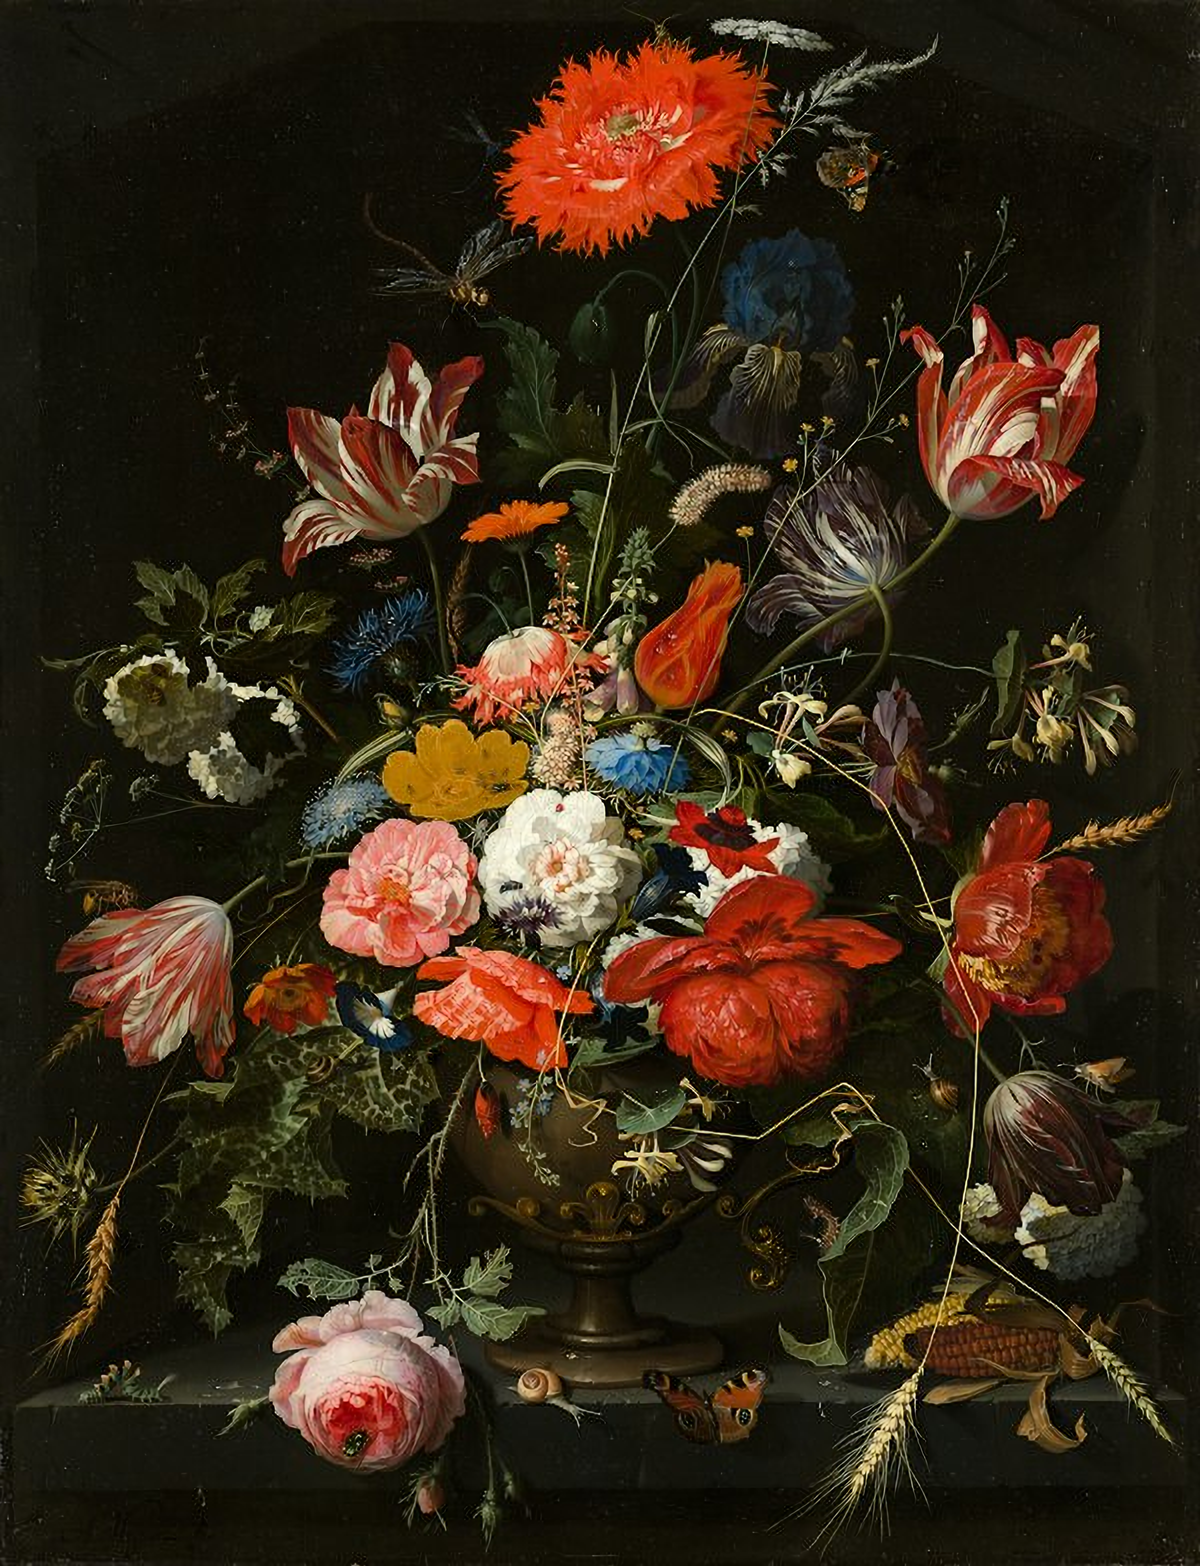

In [19]:
from PIL import Image
import os

# عرض الصورة الأصلية والصورة المرشحة بدقة عالية
image_path = './my_scaled_2x.png'

if os.path.exists(image_path):
    print("عرض الصورة النهائية بعد الترقية لمعاينتها والموافقة عليها:")
    img = Image.open(image_path)
    # عرض الصورة بحجم مناسب للمعاينة داخل المفكرة
    display(img)
else:
    print("لم يتم العثور على الصورة المرقاة بعد. يرجى التأكد من تشغيل خلية الترقية أولاً.")

In [3]:
from google.colab import files
import os

# Helper to download file if it exists
def download_file(filename, fallback_filename=None):
    if os.path.exists(filename):
        print(f"Downloading {filename}...")
        files.download(filename)
    elif fallback_filename and os.path.exists(fallback_filename):
        print(f"{filename} not found. Downloading fallback {fallback_filename}...")
        files.download(fallback_filename)
    else:
        print(f"Could not find {filename} or {fallback_filename}. Please make sure you run the upscaling cell first!")

# Download the upscaled images
download_file('./my_scaled_2x.png', './scaled_2x.png')
download_file('./my_scaled_2x_compare.png', './scaled_2x_compare.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

View the comparison image to see, visually, how our model performed (on the right) against the baseline bicubic method (left).

We can view the original image that we pulled from the URL/website using `cv2_imshow`.